# Benchmark: preliminary exploration modes

This study compares complete autospec searches with no preliminary ensemble,
with native trees, and with the optional hessboost engine. The quantities
compared are the prediction error, the error in recovering a known mean function
and the cost of the whole search, including screening and final prediction. The
simulation seeds were not held out from the choice of the screening policy, so the
results do not independently confirm that policy.

The response has arbitrary response units. Each sampling unit is an independent
row. Seven simulation seeds each provide 600 training rows and 1,200 independent
test rows for three scenarios. All modes share the rows and five-fold tuning
seed. The estimand is the expected prediction loss or mean-function error of the whole
search on a new sample. Test MSE and mean-function MSE have squared response units. Uncertainty
is Monte Carlo standard error over independent seeds; elapsed-time summaries
are descriptive because other jobs shared the machine. The claim is
methodological, not causal or a fixed-workload speed ratio.

In [1]:
import json
from pathlib import Path

import altair as alt
import polars as pl
from IPython.display import display

from bench_tables import table

alt.renderers.enable("svg")
artifact = json.loads(Path("bench_preexploration.json").read_text())
protocol = artifact["protocol"]
fields = ["scenario", "seed", "engine", "status", "mse", "signal_mse",
          "seconds", "shape_scores", "false_retained", "fits"]
frame = pl.DataFrame([{key: row.get(key) for key in fields}
                      for row in artifact["results"]])


In [2]:
# Average the three scenarios within a seed before calculating a seed SE.
metrics = ["mse", "signal_mse", "seconds", "shape_scores", "false_retained"]
seed_means = (frame.filter(pl.col("status") == "ok").group_by("engine", "seed")
              .agg(pl.len().alias("scenarios"), *[pl.col(c).mean() for c in metrics])
              .filter(pl.col("scenarios") == 3))
summary = seed_means.group_by("engine").agg(
    pl.col("mse").mean(), (pl.col("mse").std() / pl.len().sqrt()).alias("se"),
    pl.col("signal_mse").mean(), pl.col("seconds").median(),
    pl.col("shape_scores").mean())
counts = frame.group_by("engine").agg(
    (pl.col("status") != "ok").sum().alias("failures"))
summary = counts.join(summary, on="engine", how="left").sort("engine")


In [3]:
table(summary, title="Complete specification searches across three scenarios",
      subtitle="Seven paired seeds; lower error, elapsed time and search cost are better",
      stub="engine", stubhead="Screening mode",
      labels={"mse": "Test MSE", "se": "SE", "signal_mse": "Mean MSE",
              "seconds": "Seconds", "shape_scores": "Shape scores", "failures": "Failures"},
      spanners={"Squared response units": ["mse", "se", "signal_mse"],
                "Search cost": ["seconds", "shape_scores"]},
      better={"mse": "min", "signal_mse": "min", "seconds": "min",
              "shape_scores": "min", "failures": "min"}, formats={"seconds": 2, "shape_scores": 1},
      notes=["MSE is prediction loss; mean MSE compares predictions with the noise-free generating mean.",
             "SE is over seven seed means, each averaging three scenarios; only complete seed triples enter the summary.",
             "Seconds is the median of per-seed average wall time over scenarios, including screening, search, final fit and prediction.",
             "Shape scores counts evaluated candidate shapes, not iterations or low-level fits. Failures count all attempted jobs.",
             "Best values are bold at displayed precision."])

GT(_tbl_data=shape: (3, 7)
┌───────────┬──────────┬──────────┬──────────┬────────────┬──────────┬──────────────┐
│ engine    ┆ failures ┆ mse      ┆ se       ┆ signal_mse ┆ seconds  ┆ shape_scores │
│ ---       ┆ ---      ┆ ---      ┆ ---      ┆ ---        ┆ ---      ┆ ---          │
│ str       ┆ u32      ┆ f64      ┆ f64      ┆ f64        ┆ f64      ┆ f64          │
╞═══════════╪══════════╪══════════╪══════════╪════════════╪══════════╪══════════════╡
│ hessboost ┆ 0        ┆ 0.093464 ┆ 0.001137 ┆ 0.004111   ┆ 4.966397 ┆ 16.333333    │
│ native    ┆ 0        ┆ 0.093464 ┆ 0.001137 ┆ 0.004111   ┆ 6.83914  ┆ 16.333333    │
│ off       ┆ 0        ┆ 0.093464 ┆ 0.001137 ┆ 0.004111   ┆ 4.609341 ┆ 18.0         │
└───────────┴──────────┴──────────┴──────────┴────────────┴──────────┴──────────────┘, _body=<great_tables._gt_data.Body object at 0x10b7db770>, _boxhead=Boxhead([ColInfo(var='engine', type=<ColInfoTypeEnum.stub: 2>, column_label='engine', column_align='left', column_width=None, stub_level=0), ColInfo(var='failures', type=<ColInfoTypeEnum.default: 1>, column_label='Failures', column_align='right', column_width=None, stub_level=None), ColInfo(var='mse', type=<ColInfoTypeEnum.default: 1>, column_label='Test MSE', column_align='right', column_width=None, stub_level=None), ColInfo(var='se', type=<ColInfoTypeEnum.default: 1>, column_label='SE', column_align='right', column_width=None, stub_level=None), ColInfo(var='signal_mse', type=<ColInfoTypeEnum.default: 1>, column_label='Mean MSE', column_align='right', column_width=None, stub_level=None), ColInfo(var='seconds', type=<ColInfoTypeEnum.default: 1>, column_label='Seconds', column_align='right', column_width=None, stub_level=None), ColInfo(var='shape_scores', type=<ColInfoTypeEnum.default: 1>, column_label='Shape scores', column_align='right', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0x10af93d40>, _spanners=Spanners([SpannerInfo(spanner_id='Squared response units', spanner_level=0, spanner_label='Squared response units', spanner_units=None, spanner_pattern=None, vars=['mse', 'se', 'signal_mse'], built=None), SpannerInfo(spanner_id='Search cost', spanner_level=0, spanner_label='Search cost', spanner_units=None, spanner_pattern=None, vars=['seconds', 'shape_scores'], built=None)]), _heading=Heading(title='Complete specification searches across three scenarios', subtitle='Seven paired seeds; lower error, elapsed time and search cost are better', preheader=None), _stubhead='Screening mode', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10c8a4170>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10b060b30>, _source_notes=['MSE is prediction loss; mean MSE compares predictions with the noise-free generating mean.', 'SE is over seven seed means, each averaging three scenarios; only complete seed triples enter the summary.', 'Seconds is the median of per-seed average wall time over scenarios, including screening, search, final fit and prediction.', 'Shape scores counts evaluated candidate shapes, not iterations or low-level fits. Failures count all attempted jobs.', 'Best values are bold at displayed precision.'], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x10c711670>, _formats=[<great_tables._gt_data.FormatInfo object at 0x10b7db320>, <great_tables._gt_data.FormatInfo object at 0x10cbe76b0>, <great_tables._gt_data.FormatInfo object at 0x10cbe72f0>, <great_tables._gt_data.FormatInfo object at 0x10cbe6ea0>, <great_tables._gt_data.FormatInfo object at 0x10cbe7620>, <great_tables._gt_data.FormatInfo object at 0x10cbe5eb0>], _substitutions=[<great_tables._gt_data.FormatInfo object at 0x10cbe7110>], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), tab

All modes have the same test errors on these paired samples. Screening evaluates
fewer shape candidates, but the additional ensemble and pair checks can cost
more than the comparisons they remove. This evidence supports the `off` option
for inexpensive searches; it does not establish a universal screening speedup.
The table "Prediction and structure by generating process" separates the jump,
interaction and correlated predictor settings.

## Generating processes and protocol

All scenarios begin with six independent uniform $(-1,1)$ columns and the
base mean $2x_0+\sin(3x_1)$. The jump scenario adds $2\,1\{x_2>0.2\}$;
the interaction scenario adds $2x_2x_3$. In the correlated scenario, `x2` is
replaced by `x0` plus Gaussian noise with standard deviation 0.05, while the
mean remains the base mean. Every response adds Gaussian noise with standard
deviation 0.3. In the correlated design, a retained `x2` is an informative
proxy, so its count as a non-generating variable is not a false causal discovery.

The table "Recorded simulation and search settings" lists the settings stored with
the results. The order in which the engines run rotates deterministically by seed
and is not chosen from test results.

In [4]:
settings = [{"setting": key, "value": str(protocol[key])}
            for key in ("train_rows", "test_rows", "columns", "seeds", "family",
                        "budget", "interactions", "engines", "noise_sd", "order", "warmup")]
table(pl.DataFrame(settings), title="Recorded simulation and search settings",
      subtitle="Identical training/test rows and tuning seeds across modes",
      stub="setting", stubhead="Setting", labels={"value": "Recorded value"},
      notes=["Rows are split by independent simulation; test responses are excluded from every search.",
             "Each engine has one wall-time observation per scenario/seed; system load is not controlled."])


GT(_tbl_data=shape: (11, 2)
┌──────────────┬─────────────────────────────────┐
│ setting      ┆ value                           │
│ ---          ┆ ---                             │
│ str          ┆ str                             │
╞══════════════╪═════════════════════════════════╡
│ train_rows   ┆ 600                             │
│ test_rows    ┆ 1200                            │
│ columns      ┆ 6                               │
│ seeds        ┆ 7                               │
│ family       ┆ Gaussian                        │
│ …            ┆ …                               │
│ interactions ┆ adopt                           │
│ engines      ┆ ['off', 'native', 'hessboost']  │
│ noise_sd     ┆ 0.3                             │
│ order        ┆ rotate the engine order by see… │
│ warmup       ┆ imports only; no model warmup;… │
└──────────────┴─────────────────────────────────┘, _body=<great_tables._gt_data.Body object at 0x10c96fdd0>, _boxhead=Boxhead([ColInfo(var='setting', type=<ColInfoTypeEnum.stub: 2>, column_label='setting', column_align='left', column_width=None, stub_level=0), ColInfo(var='value', type=<ColInfoTypeEnum.default: 1>, column_label='Recorded value', column_align='left', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0x10cbe7530>, _spanners=Spanners([]), _heading=Heading(title='Recorded simulation and search settings', subtitle='Identical training/test rows and tuning seeds across modes', preheader=None), _stubhead='Setting', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10b7dba10>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10cbe7c80>, _source_notes=['Rows are split by independent simulation; test responses are excluded from every search.', 'Each engine has one wall-time observation per scenario/seed; system load is not controlled.'], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x10cbe6480>, _formats=[], _substitutions=[<great_tables._gt_data.FormatInfo object at 0x10ce9d130>], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_top_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_top_color=OptionsInfo(scss=True, category='table', type='value', value='#A8A8A8'), table_border_right_style=OptionsInfo(scss=True, category='table', type='value', value='none'), table_border_right_width=OptionsInfo(scss=True, category='table', t

The main call for each mode is the following; `train` and `test` are
independent samples from the stated process. The page reads the saved results
instead of repeating the searches:

```python
rec = mb.autospec(train, "y", family=mb.Gaussian(), budget=200,
                  interactions="adopt", preexploration=engine, seed=seed)
fit = rec.fit(train)
predicted = fit.predict(test.drop("y"))
```

## A recorded result

A record contains the selected formula and iteration, the cost reported by
autospec, the number of evaluated shape candidates, prediction and
mean-function errors, and retained variables. `fits` uses autospec's accounting:
one-term backfitting, which refits a single term while the other terms are held
fixed, can cost a fraction of a full-model fit, so `fits` is not a literal count
of all fitting calls. Preliminary importance and H² values are retained in the
record's `exploration` object for diagnosis.

In [5]:
example = next(row for row in artifact["results"]
               if row["engine"] == "native" and row["scenario"] == "interaction"
               and row["status"] == "ok")
record = [{"field": key, "value": str(example[key])}
          for key in ("scenario", "seed", "engine", "formula", "mstop", "fits",
                      "shape_scores", "mse", "signal_mse", "oracle_mse",
                      "retained_variables", "true_variables", "status")]
table(pl.DataFrame(record), title="One native-screening result",
      subtitle="A single training/test replicate; squared-error fields use squared response units",
      stub="field", stubhead="Field", labels={"value": "Recorded value"},
      notes=["oracle_mse is the empirical loss of the known mean on these same test responses, not a fitted competitor."])


GT(_tbl_data=shape: (13, 2)
┌────────────────────┬─────────────────────────────────┐
│ field              ┆ value                           │
│ ---                ┆ ---                             │
│ str                ┆ str                             │
╞════════════════════╪═════════════════════════════════╡
│ scenario           ┆ interaction                     │
│ seed               ┆ 0                               │
│ engine             ┆ native                          │
│ formula            ┆ y ~ bbs(x0, df=4.0) + bbs(x1, … │
│ mstop              ┆ 67                              │
│ …                  ┆ …                               │
│ signal_mse         ┆ 0.003325622655712131            │
│ oracle_mse         ┆ 0.09293678750355765             │
│ retained_variables ┆ ['x0', 'x1', 'x2', 'x3']        │
│ true_variables     ┆ ['x0', 'x1', 'x2', 'x3']        │
│ status             ┆ ok                              │
└────────────────────┴─────────────────────────────────┘, _body=<great_tables._gt_data.Body object at 0x10ca044d0>, _boxhead=Boxhead([ColInfo(var='field', type=<ColInfoTypeEnum.stub: 2>, column_label='field', column_align='left', column_width=None, stub_level=0), ColInfo(var='value', type=<ColInfoTypeEnum.default: 1>, column_label='Recorded value', column_align='left', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0x10ce9e060>, _spanners=Spanners([]), _heading=Heading(title='One native-screening result', subtitle='A single training/test replicate; squared-error fields use squared response units', preheader=None), _stubhead='Field', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10b7dbbf0>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10ce9e7b0>, _source_notes=['oracle_mse is the empirical loss of the known mean on these same test responses, not a fitted competitor.'], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x10ce9e660>, _formats=[], _substitutions=[<great_tables._gt_data.FormatInfo object at 0x10ce9d0a0>], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_top_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_top_color=OptionsInfo(scss=True, category='table', type='value', value='#A8A8A8'), table_border_right_style=OptionsInfo(scss=True, category='table', type='value', value='none'), table_border_right_width=OptionsInfo(s

## Errors and comparison counts by scenario

The mean function is known, so its estimation error can be separated from
observation noise. Scores are averaged over seven training/test replicates.
A count of extra retained variables measures formula complexity relative to
the generating variables, including the proxy in the correlated design.


In [6]:
scenario_summary = frame.filter(pl.col("status") == "ok").group_by("scenario", "engine").agg(
    pl.col("mse").mean(), (pl.col("mse").std() / pl.len().sqrt()).alias("se"),
    pl.col("signal_mse").mean(), pl.col("shape_scores").mean(),
    pl.col("false_retained").mean()).sort("scenario", "engine")
table(scenario_summary, title="Prediction and structure by generating process",
      subtitle="Seven seeds per cell; lower errors and fewer unnecessary terms are better",
      stub="engine", stubhead="Mode", group="scenario",
      labels={"mse": "Test MSE", "se": "SE", "signal_mse": "Mean MSE",
              "shape_scores": "Shape scores", "false_retained": "Extra variables"},
      better={"mse": "min", "signal_mse": "min", "shape_scores": "min", "false_retained": "min"},
      formats={"shape_scores": 1, "false_retained": 2},
      notes=["Errors and their SE have squared response units; means and SE are over independent seeds within a scenario.",
             "Extra variables are retained names absent from the generating mean; the correlated proxy can still carry useful predictive information."])


GT(_tbl_data=shape: (9, 7)
┌─────────────┬───────────┬──────────┬──────────┬────────────┬──────────────┬────────────────┐
│ scenario    ┆ engine    ┆ mse      ┆ se       ┆ signal_mse ┆ shape_scores ┆ false_retained │
│ ---         ┆ ---       ┆ ---      ┆ ---      ┆ ---        ┆ ---          ┆ ---            │
│ str         ┆ str       ┆ f64      ┆ f64      ┆ f64        ┆ f64          ┆ f64            │
╞═════════════╪═══════════╪══════════╪══════════╪════════════╪══════════════╪════════════════╡
│ correlated  ┆ hessboost ┆ 0.092371 ┆ 0.000908 ┆ 0.002033   ┆ 16.285714    ┆ 0.428571       │
│ correlated  ┆ native    ┆ 0.092371 ┆ 0.000908 ┆ 0.002033   ┆ 16.285714    ┆ 0.428571       │
│ correlated  ┆ off       ┆ 0.092371 ┆ 0.000908 ┆ 0.002033   ┆ 18.0         ┆ 0.428571       │
│ interaction ┆ hessboost ┆ 0.091678 ┆ 0.001448 ┆ 0.00298    ┆ 16.857143    ┆ 0.0            │
│ interaction ┆ native    ┆ 0.091678 ┆ 0.001448 ┆ 0.00298    ┆ 16.857143    ┆ 0.0            │
│ interaction ┆ off       ┆ 0.091678 ┆ 0.001448 ┆ 0.00298    ┆ 18.0         ┆ 0.0            │
│ step        ┆ hessboost ┆ 0.096342 ┆ 0.001916 ┆ 0.007319   ┆ 15.857143    ┆ 0.0            │
│ step        ┆ native    ┆ 0.096342 ┆ 0.001916 ┆ 0.007319   ┆ 15.857143    ┆ 0.0            │
│ step        ┆ off       ┆ 0.096342 ┆ 0.001916 ┆ 0.007319   ┆ 18.0         ┆ 0.0            │
└─────────────┴───────────┴──────────┴──────────┴────────────┴──────────────┴────────────────┘, _body=<great_tables._gt_data.Body object at 0x10ce9f4d0>, _boxhead=Boxhead([ColInfo(var='scenario', type=<ColInfoTypeEnum.row_group: 3>, column_label='scenario', column_align='left', column_width=None, stub_level=None), ColInfo(var='engine', type=<ColInfoTypeEnum.stub: 2>, column_label='engine', column_align='left', column_width=None, stub_level=0), ColInfo(var='mse', type=<ColInfoTypeEnum.default: 1>, column_label='Test MSE', column_align='right', column_width=None, stub_level=None), ColInfo(var='se', type=<ColInfoTypeEnum.default: 1>, column_label='SE', column_align='right', column_width=None, stub_level=None), ColInfo(var='signal_mse', type=<ColInfoTypeEnum.default: 1>, column_label='Mean MSE', column_align='right', column_width=None, stub_level=None), ColInfo(var='shape_scores', type=<ColInfoTypeEnum.default: 1>, column_label='Shape scores', column_align='right', column_width=None, stub_level=None), ColInfo(var='false_retained', type=<ColInfoTypeEnum.default: 1>, column_label='Extra variables', column_align='right', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0x10c93b0e0>, _spanners=Spanners([]), _heading=Heading(title='Prediction and structure by generating process', subtitle='Seven seeds per cell; lower errors and fewer unnecessary terms are better', preheader=None), _stubhead='Mode', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10ce9f9e0>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10ce9f8c0>, _source_notes=['Errors and their SE have squared response units; means and SE are over independent seeds within a scenario.', 'Extra variables are retained names absent from the generating mean; the correlated proxy can still carry useful predictive information.'], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x10ce9f770>, _formats=[<great_tables._gt_data.FormatInfo object at 0x10b7dadb0>, <great_tables._gt_data.FormatInfo object at 0x10b7db410>, <great_tables._gt_data.FormatInfo object at 0x10ce9f5c0>, <great_tables._gt_data.FormatInfo object at 0x10ce9f3e0>, <great_tables._gt_data.FormatInfo object at 0x10ce9fa70>, <great_tables._gt_data.FormatInfo object at 0x10ce9f860>, <great_tables._gt_data.FormatInfo object at 0x10ce9fb00>, <great_tables._gt_data.FormatInfo object at 0x10ce9fbc0>, <great_tables._gt_data.FormatInfo object at 0x10ce9fd40>, <great_tables._gt_data.FormatInfo object at 0x10ce9fc20>, <great_tables._gt_data.FormatInfo object at 0x10ce9fda0>, <great_tables._gt_data.FormatInfo object 

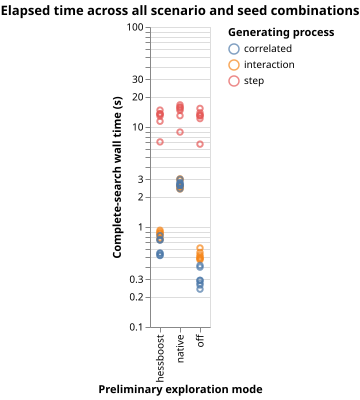

In [7]:
base = frame.filter(pl.col("engine") == "off").select(
    "scenario", "seed", pl.col("mse").alias("off_mse"))
paired = frame.join(base, on=["scenario", "seed"])
max_gap = paired.select((pl.col("mse") - pl.col("off_mse")).abs().max()).item()
min_shapes = frame.filter(pl.col("engine") != "off")["shape_scores"].min()
max_shapes = frame.filter(pl.col("engine") != "off")["shape_scores"].max()
chart = alt.Chart(frame).mark_point(opacity=0.7).encode(
    x=alt.X("engine:N", title="Preliminary exploration mode"),
    y=alt.Y("seconds:Q", title="Complete-search wall time (s)", scale=alt.Scale(type="log")),
    color=alt.Color("scenario:N", title="Generating process"),
    tooltip=["scenario", "seed", "engine", alt.Tooltip("seconds:Q", format=".2f")],
).properties(title="Elapsed time across all scenario and seed combinations")
display(chart)


The largest absolute paired test-MSE difference from `off` is
{eval}`f"{max_gap:.6f}"` squared response units. The preliminary engines use
{eval}`int(min_shapes)`–{eval}`int(max_shapes)` shape scores instead of the 18 (six columns times three
shapes) scored by `off`.
The elapsed-time plot shows why fewer comparisons do not imply lower whole-
workflow cost: screening and additional pair validation are also timed.
No interval for a portable speed ratio is inferred from these measurements.

## Scope of the comparison

The seven seeds cover three mechanisms: a jump, an interaction and a correlated
proxy predictor.
They cannot establish generalization to new data sets or guarantee that the
screen retains every useful candidate. Correlated predictors and a weak
preliminary fit are especially relevant limitations. The
[body-fat case](autospec_bodyfat.ipynb) supplies a real-data prediction workflow,
and the [shape-and-interaction case](preexploration_shapes.ipynb) makes the
selected effects visible.

## Reproduction

The results are read from `bench_preexploration.json`, written by
`benches/bench_preexploration.py`. To regenerate them from a source checkout with
the optional hessboost engine:

```bash
maturin develop --release --features hessboost
RAYON_NUM_THREADS=1 OMP_NUM_THREADS=1 OPENBLAS_NUM_THREADS=1 python benches/bench_preexploration.py --seeds 7   --out docs/book/cases/bench_preexploration.json
```

A build without the `hessboost` feature can run `--engines off,native`, the modes
with no preliminary ensemble and with native boosted trees. An unavailable
requested engine is recorded as a failure and counted in the failure column. The
results file includes per-row measurement times, input and output digests, source
and runner hashes, compiler and build identity, package versions and thread
settings. Memory is not measured.